###H1N1 Vaccine Prediction project.

- Pandas: Used for loading, cleaning and manipulating the dataset.
- NumPy: Used for numerical calculations and array operations.
- Matplotlib: Used for creating graphs and visualisations.
- Seaborn: Used for statistical data visualisation.
- Google Colab Files: Used to upload the dataset directly from the computer.
- Scikit-learn: Used for data preprocessing, splitting the dataset, building machine learning models and evaluating their performance.
- SimpleImputer: Used to handle missing values in the dataset.
- OneHotEncoder: Converts categorical variables into numerical format.
- StandardScaler: Standardises numerical features.
- ColumnTransformer and Pipeline: Organise preprocessing and machine learning steps.
- Logistic Regression, Decision Tree, Random Forest and Gradient Boosting: Classification algorithms used to predict H1N1 vaccination.
- Evaluation Metrics: Accuracy, precision, recall, F1-score, ROC-AUC and confusion matrix are used to evaluate model performance.
- Warnings: Used to suppress unnecessary warning messages during execution.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving dataset_B_testing.csv to dataset_B_testing.csv
Dataset uploaded successfully!
Dataset Shape: (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Female,"<= $75,000, Above Poverty",Not Married,Own,Not in Labor Force,"MSA, Principle City",0.0,0.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,Female,NaN,NaN,NaN,NaN,"MSA, Not Principle City",0.0,0.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Male,NaN,Married,Own,Not in Labor Force,"MSA, Principle City",1.0,0.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,1.0,0.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Own,Employed,Non-MSA,0.0,0.0,wholesale,0


In [ ]:
print("Dataset Information:")
df.info()

print("\nDataset Description:")
display(df.describe(include='all'))

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4749 entries, 0 to 4748
Data columns (total 30 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4749 non-null   int64  
 1   h1n1_concern                   4728 non-null   float64
 2   h1n1_knowledge                 4731 non-null   float64
 3   behavioral_antiviral_meds      4735 non-null   float64
 4   behavioral_avoidance           4702 non-null   float64
 5   behavioral_face_mask           4746 non-null   float64
 6   behavioral_wash_hands          4743 non-null   float64
 7   behavioral_large_gatherings    4722 non-null   float64
 8   behavioral_outside_home        4737 non-null   float64
 9   behavioral_touch_face          4719 non-null   float64
 10  doctor_recc_h1n1               4404 non-null   float64
 11  child_under_6_months           4594 non-null   float64
 12  health_worker              

,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
count,4749.000000,4728.000000,4731.000000,4735.000000,4702.000000,4746.000000,4743.000000,4722.000000,4737.000000,4719.000000,...,4749,3952,4480,4370,4472,4749,4699.000000,4699.000000,2344,4749.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,3,2,2,3,3,NaN,NaN,21,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Female,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",NaN,NaN,healthcare,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2820,2248,2445,3379,2374,2036,NaN,NaN,529,NaN
mean,7131.000000,1.690990,1.282181,0.052587,0.730540,0.080700,0.837234,0.364888,0.343044,0.690189,...,NaN,NaN,NaN,NaN,NaN,NaN,0.874867,0.527559,NaN,0.374184
std,1371.062544,0.914997,0.625445,0.223231,0.443726,0.272402,0.369191,0.481450,0.474776,0.462465,...,NaN,NaN,NaN,NaN,NaN,NaN,0.735933,0.923325,NaN,0.667275
min,4757.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,0.000000
25%,5944.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,0.000000
50%,7131.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,0.000000
75%,8318.000000,2.000000,2.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,1.000000



Dataset Columns:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions']

Duplicate Rows: 0


,Missing Values,Missing Percentage
employment_sector,2405,50.642240
health_insurance,1982,41.735102
income_poverty,797,16.782481
rent_or_own,379,7.980628
doctor_recc_h1n1,345,7.264687
employment_status,277,5.832807
education,269,5.664350
marital_status,269,5.664350
child_under_6_months,155,3.263845
health_worker,149,3.137503


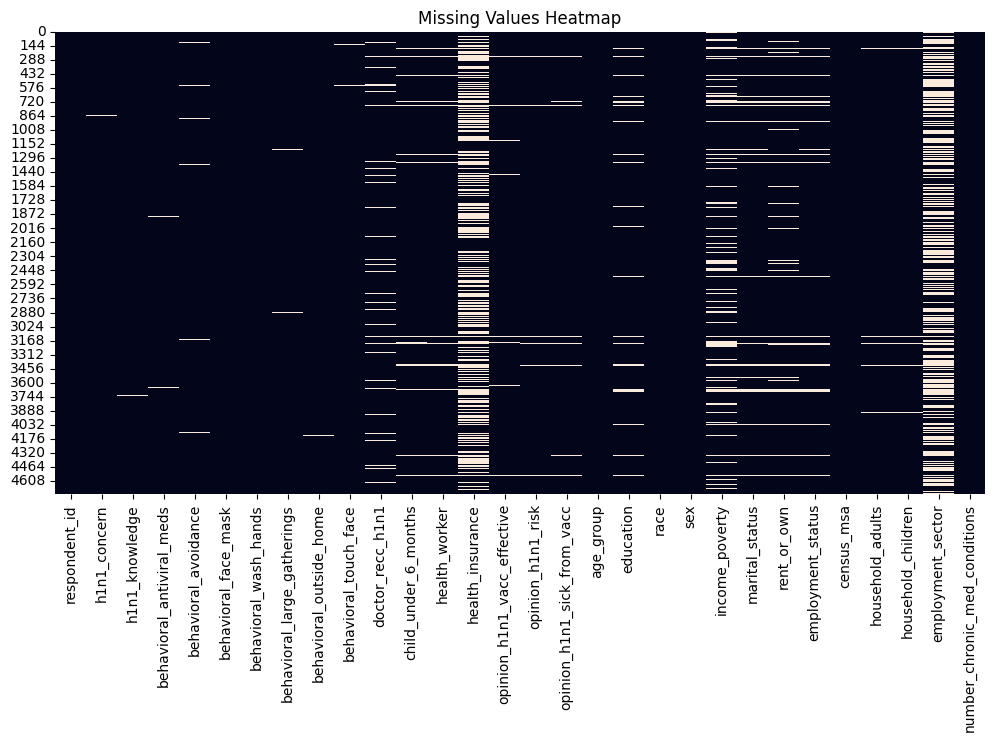

In [ ]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': df.isnull().mean() * 100
})

display(missing.sort_values(
    by='Missing Percentage',
    ascending=False
))

plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

In [ ]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving dataset_B_training.csv to dataset_B_training (1).csv
Dataset uploaded successfully!
Dataset Shape: (4756, 31)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Vaccination Percentage:
h1n1_vaccine
0    60.59714
1    39.40286
Name: proportion, dtype: float64


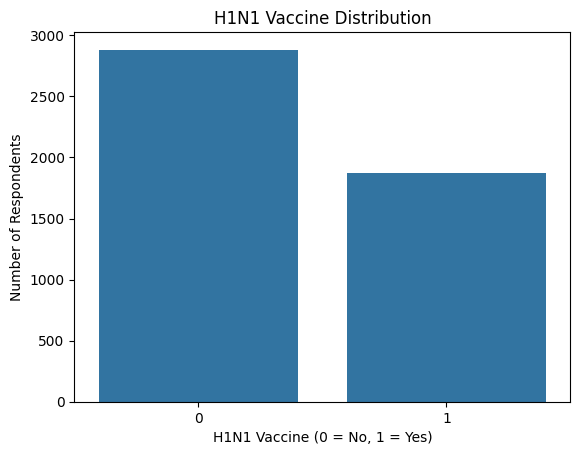

In [ ]:
print(df['h1n1_vaccine'].value_counts())

print("\nVaccination Percentage:")
print(df['h1n1_vaccine'].value_counts(normalize=True) * 100)

sns.countplot(data=df, x='h1n1_vaccine')

plt.title("H1N1 Vaccine Distribution")
plt.xlabel("H1N1 Vaccine (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")
plt.show()

In [ ]:
X = df.drop(columns=['respondent_id', 'h1n1_vaccine'])

y = df['h1n1_vaccine']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (4756, 29)
Target: (4756,)


In [ ]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'household_adults', 'household_children', 'number_chronic_med_conditions']

Categorical Features:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (3329, 29)
Testing Shape: (1427, 29)


In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

display(results_df.sort_values(
    by='ROC AUC',
    ascending=False
))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
3,Gradient Boosting,0.768045,0.746269,0.622776,0.678952,0.819578
0,Logistic Regression,0.748423,0.668885,0.715302,0.691316,0.817933
2,Random Forest,0.756833,0.737307,0.594306,0.658128,0.801368
1,Decision Tree,0.672039,0.581597,0.596085,0.588752,0.658736


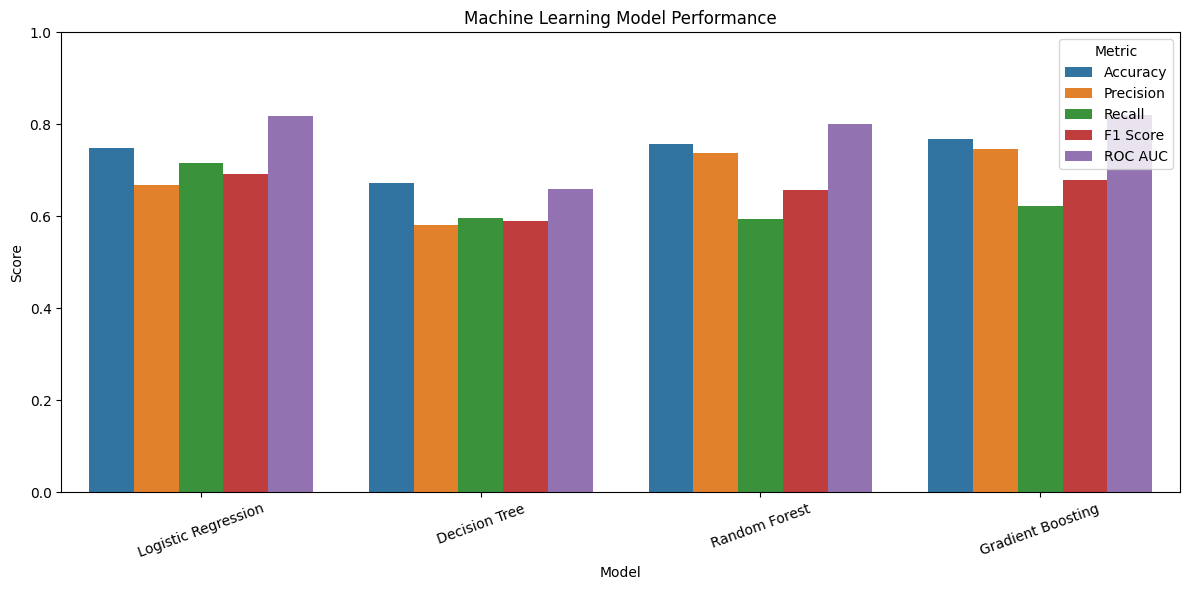

In [ ]:
results_melted = results_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title("Machine Learning Model Performance")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Best Model: Gradient Boosting

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.86      0.82       865
           1       0.75      0.62      0.68       562

    accuracy                           0.77      1427
   macro avg       0.76      0.74      0.75      1427
weighted avg       0.77      0.77      0.76      1427



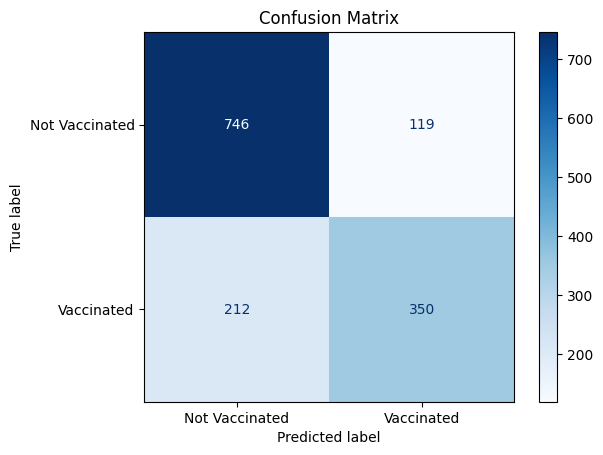

In [ ]:
best_model_name = results_df.sort_values(
    by='ROC AUC',
    ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Not Vaccinated', 'Vaccinated'],
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.show()

### Random Forest Feature Importance Analysis

In this section, we use the trained Random Forest classification model to identify the most important features influencing H1N1 vaccine prediction.

The feature importance values indicate how much each input variable contributes to the model's predictive decisions.

The code extracts the feature names from the preprocessing pipeline and retrieves their corresponding importance scores from the trained Random Forest classifier.

The features are then sorted in descending order of importance, and the top 15 features are displayed in a table and visualised using a horizontal bar chart.

Key objectives:

- Identify the most influential features in vaccination prediction.
- Rank features according to their importance scores.
- Display the top 15 features in a table.
- Visualise feature importance using a bar chart.
- Understand which personal, behavioural and health-related factors contribute most to the model's predictions.

Expected outcome: The analysis provides insights into the factors that are most useful for predicting H1N1 vaccination behaviour.


,Feature,Importance
9,num__doctor_recc_h1n1,0.101308
14,num__opinion_h1n1_risk,0.101136
13,num__opinion_h1n1_vacc_effective,0.078723
15,num__opinion_h1n1_sick_from_vacc,0.038342
0,num__h1n1_concern,0.037612
1,num__h1n1_knowledge,0.028491
16,num__household_adults,0.027619
18,num__number_chronic_med_conditions,0.027011
17,num__household_children,0.025155
11,num__health_worker,0.023578


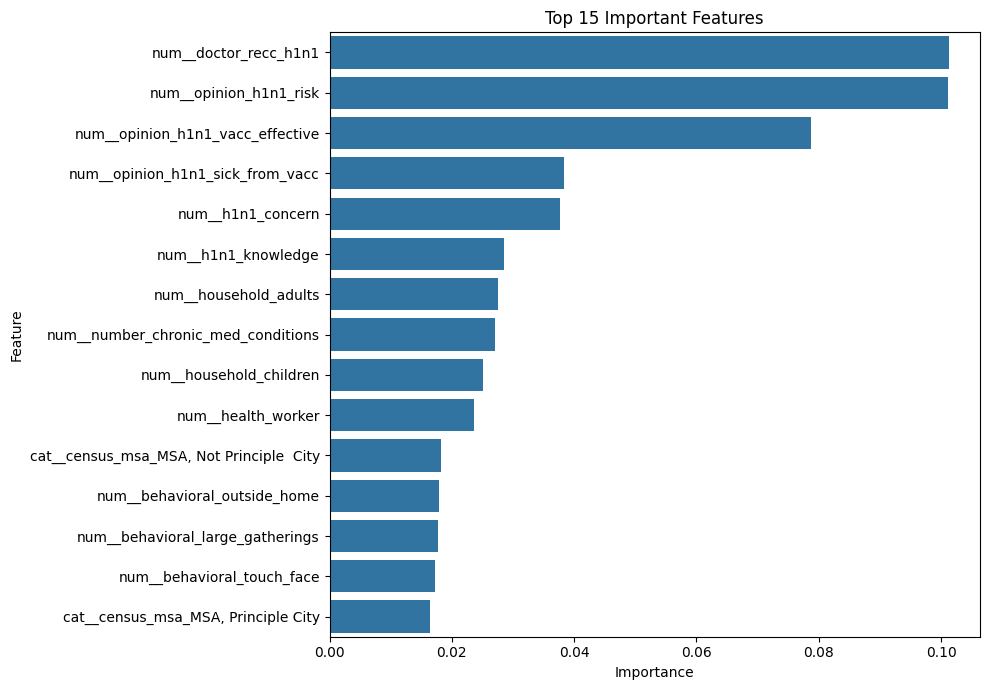

In [ ]:
rf_model = trained_models['Random Forest']

feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = rf_model.named_steps[
    'classifier'
].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()

### Financial Impact Analysis

In this section, we analyse the financial costs associated with H1N1 vaccination and hospitalisation. The cost of one H1N1 vaccine is $500, while the estimated cost of hospitalisation due to H1N1 influenza is $25,000.

The analysis calculates the total number of respondents, the number of vaccinated and non-vaccinated individuals, and the estimated vaccination costs.

It also compares the cost of vaccinating individuals with the cost of hospitalisation to understand the potential economic benefits of vaccination.

Key objectives:

- Calculate the total number of respondents.
- Identify vaccinated and non-vaccinated individuals.
- Estimate the cost of vaccinating the entire population.
- Calculate the vaccination expenditure for respondents who received the vaccine.
- Compare vaccination costs with hospitalisation costs.

Expected outcome: This analysis demonstrates the financial difference between vaccination and hospitalisation. One hospitalisation costs 50 times as much as one vaccine.


In [ ]:
vaccine_cost = 500
hospitalisation_cost = 25000

total_respondents = len(df)

vaccinated = (df['h1n1_vaccine'] == 1).sum()
not_vaccinated = (df['h1n1_vaccine'] == 0).sum()

total_vaccine_cost = vaccinated * vaccine_cost

total_population_vaccine_cost = total_respondents * vaccine_cost

hospitalisation_cost_per_person = hospitalisation_cost

print("Total Respondents:", total_respondents)

print("Vaccinated Respondents:", vaccinated)

print("Not Vaccinated Respondents:", not_vaccinated)

print("\nCost of vaccinating all respondents: $",
      total_population_vaccine_cost)

print("Cost of vaccinating actual vaccinated respondents: $",
      total_vaccine_cost)

print("One hospitalisation cost: $",
      hospitalisation_cost)

print("Hospitalisation cost is",
      hospitalisation_cost / vaccine_cost,
      "times the vaccine cost.")

Total Respondents: 4756
Vaccinated Respondents: 1874
Not Vaccinated Respondents: 2882

Cost of vaccinating all respondents: $ 2378000
Cost of vaccinating actual vaccinated respondents: $ 937000
One hospitalisation cost: $ 25000
Hospitalisation cost is 50.0 times the vaccine cost.


### Final Model Performance Evaluation

In this section, we evaluate and compare the performance of all trained machine learning classification models. The evaluation uses five performance metrics: Accuracy, Precision, Recall, F1-Score and ROC-AUC.

These metrics help determine how accurately each model predicts whether a respondent received the H1N1 vaccine.

- Accuracy: Measures the overall percentage of correct predictions.
- Precision: Measures how many predicted vaccinated respondents were actually vaccinated.
- Recall: Measures how many actual vaccinated respondents were correctly identified.
- F1-Score: Provides a balance between precision and recall.
- ROC-AUC: Measures how effectively the model distinguishes between vaccinated and non-vaccinated respondents.

The results are displayed for each model, allowing us to compare their strengths and weaknesses and identify the most suitable model for H1N1 vaccine prediction.

In [ ]:
print("FINAL MODEL RESULTS")

for index, row in results_df.iterrows():

    print("\nModel:", row['Model'])
    print("Accuracy:", round(row['Accuracy'], 4))
    print("Precision:", round(row['Precision'], 4))
    print("Recall:", round(row['Recall'], 4))
    print("F1 Score:", round(row['F1 Score'], 4))
    print("ROC AUC:", round(row['ROC AUC'], 4))

FINAL MODEL RESULTS

Model: Logistic Regression
Accuracy: 0.7484
Precision: 0.6689
Recall: 0.7153
F1 Score: 0.6913
ROC AUC: 0.8179

Model: Decision Tree
Accuracy: 0.672
Precision: 0.5816
Recall: 0.5961
F1 Score: 0.5888
ROC AUC: 0.6587

Model: Random Forest
Accuracy: 0.7568
Precision: 0.7373
Recall: 0.5943
F1 Score: 0.6581
ROC AUC: 0.8014

Model: Gradient Boosting
Accuracy: 0.768
Precision: 0.7463
Recall: 0.6228
F1 Score: 0.679
ROC AUC: 0.8196


In [ ]:
print("H1N1 VACCINE PREDICTION - CONCLUSION")

print("Best Performing Model:", best_model_name)

print("Best Model ROC AUC:",
      round(
          results_df.loc[
              results_df['Model'] == best_model_name,
              'ROC AUC'
          ].iloc[0], 4
      ))

print("Important features influencing vaccination:")

display(feature_importance.head(10))

H1N1 VACCINE PREDICTION - CONCLUSION
Best Performing Model: Gradient Boosting
Best Model ROC AUC: 0.8196
Important features influencing vaccination:


,Feature,Importance
9,num__doctor_recc_h1n1,0.101308
14,num__opinion_h1n1_risk,0.101136
13,num__opinion_h1n1_vacc_effective,0.078723
15,num__opinion_h1n1_sick_from_vacc,0.038342
0,num__h1n1_concern,0.037612
1,num__h1n1_knowledge,0.028491
16,num__household_adults,0.027619
18,num__number_chronic_med_conditions,0.027011
17,num__household_children,0.025155
11,num__health_worker,0.023578


### Final Conclusion

In this section, we evaluate the overall results of the H1N1 Vaccine Prediction project. The best-performing machine learning model is identified using the ROC-AUC score. We also examine the top 10 important features from the Random Forest model to understand which factors contribute most to predicting whether a respondent received the H1N1 vaccine.

This analysis helps us understand vaccination patterns, identify influential factors and assess the effectiveness of machine learning classification models in predicting vaccination behaviour.